In [1]:
print("hello")

hello


In [2]:
import re
from collections import Counter

from finsent.config import PROCESSED_DIR, RAW_DIR
from finsent.data.clean import clean_text

import pandas as pd
import matplotlib.pyplot as plt

df1=pd.read_csv(RAW_DIR / "tfns.csv")
df2=pd.read_csv(PROCESSED_DIR / "tfns_clean.csv")

print(df1.shape)
print(df2.shape)

(11931, 3)
(11775, 3)


In [3]:
raw=df1.copy()
before=raw.shape[0]
raw=raw.dropna(subset=["text","label"])
raw["text"]=raw.text.apply(clean_text)
raw = raw[raw["text"] != ""]
raw = raw.drop_duplicates(subset=["text","label","split"], keep="first")

label_count=raw.groupby("text")["label"].nunique()
conflict=label_count[label_count>1].index
raw=raw[~raw.text.isin(conflict)]

dup_split=raw["split"]=="validation"
val_texts = set(raw.loc[dup_split, "text"])
in_train=raw["split"]=="train"

raw=raw[~(in_train & raw["text"].isin(val_texts))]
raw=raw.reset_index(drop=True)
print(f"train/val overlap: removed {before - len(raw)} ({len(raw)} left)")

train/val overlap: removed 156 (11775 left)


In [4]:
print(len(raw)==len(df2))

True


In [5]:
props = df2.groupby("split")["label"].value_counts(normalize=True)
print(props)

split       label   
train       neutral     0.646239
            positive    0.202681
            negative    0.151080
validation  neutral     0.654882
            positive    0.199916
            negative    0.145202
Name: proportion, dtype: float64


In [6]:
table = props.unstack()
print(table)


label       negative   neutral  positive
split                                   
train       0.151080  0.646239  0.202681
validation  0.145202  0.654882  0.199916


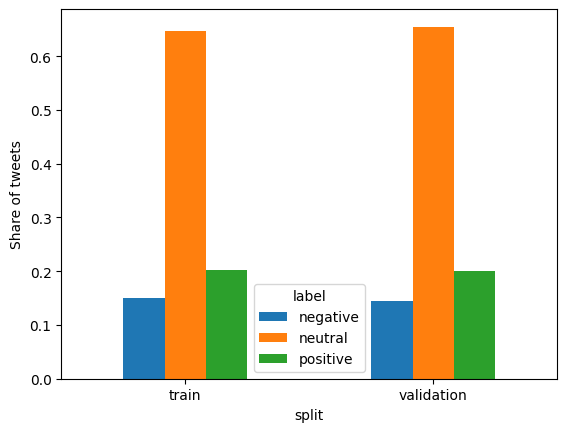

In [7]:
table.plot(kind="bar")
plt.ylabel("Share of tweets")
plt.xticks(rotation=0)
plt.show()

In [8]:
from transformers import AutoTokenizer

tokenizer=AutoTokenizer.from_pretrained("ProsusAI/finbert")


d:\finsent\fs\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [9]:
print(raw["text"][0])
b=tokenizer(raw["text"][0])
print(b["input_ids"])
print(tokenizer.convert_ids_to_tokens(b["input_ids"]))

$BYND - JPMorgan reels in expectations on Beyond Meat
[101, 1002, 2011, 4859, 1011, 16545, 5302, 16998, 15934, 2015, 1999, 10908, 2006, 3458, 6240, 102]
['[CLS]', '$', 'by', '##nd', '-', 'jp', '##mo', '##rgan', 'reel', '##s', 'in', 'expectations', 'on', 'beyond', 'meat', '[SEP]']


In [10]:
    df3=tokenizer(df2["text"].tolist())
    print(len(df3["input_ids"]))
        

11775


In [11]:
print(df3["input_ids"][0])
b=[len(x) for x in df3["input_ids"] ]
print(b[:10])
lengths=pd.Series(b)
print(len(lengths))
lengths.describe(percentiles=[0.5,0.95,0.99])

[101, 1002, 2011, 4859, 1011, 16545, 5302, 16998, 15934, 2015, 1999, 10908, 2006, 3458, 6240, 102]
[16, 21, 24, 12, 16, 24, 9, 10, 12, 24]
11775


count    11775.000000
mean        19.643567
std          7.201657
min          3.000000
50%         19.000000
95%         32.000000
99%         38.000000
max         81.000000
dtype: float64

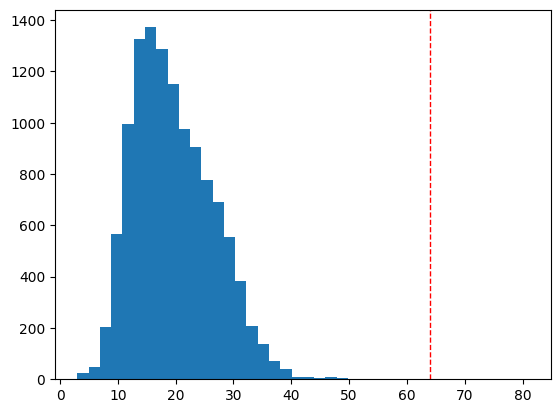

In [12]:
plt.hist(lengths, bins=40)
plt.axvline(64, color="red", linestyle="dashed", linewidth=1)
plt.show()



In [13]:
ticker=re.compile(r"(\$[A-Za-z]+)")
tickers=pd.Series(df2["text"].str.findall(ticker))

print( tickers.head())

counts = tickers.str.len()
print(f"1+ tickers: {(counts > 0).mean():.1%}")
print(f"2+ tickers: {(counts > 1).mean():.1%}")

0         [$BYND]
1    [$CCL, $RCL]
2           [$CX]
3          [$ESS]
4         [$FNKO]
Name: text, dtype: object
1+ tickers: 14.9%
2+ tickers: 2.3%


In [14]:
ticker_counts = tickers.explode().dropna().str.upper().value_counts()
print(f"unique tickers: {len(ticker_counts)}")
ticker_counts.head(20)

unique tickers: 1408


text
$SPY      36
$TSLA     26
$SUMRX    16
$UBER     15
$ECONX    15
$SCANX    15
$AAPL     15
$NVDA     14
$USO      13
$IWM      12
$AMTD     11
$AMZN     11
$UNG      11
$MDCO     11
$EBAY      9
$BA        9
$WORK      9
$DIS       9
$COMDX     8
$TIF       8
Name: count, dtype: int64

In [15]:
for each_label in ["negative", "neutral", "positive"]:
    a=df2[df2["label"]==each_label]
    b=a.sample(8, random_state=42)
    print("------"+each_label.upper()+"---------")
    for i in b["text"]:
        print(i)


    

------NEGATIVE---------
Vir Biotechnology EPS misses by $0.52, misses on revenue
FTC's Look Into Facebook A 'Negative Development,' Says RBC's Mahaney
$F - Ford's Value Has Tanked: Recovery Looks Poor. #economy #stocks #markets
China Virus Crisis Roils Supply Chains for Global Manufacturers
$MIME - Mimecast -7.6% after downside Q4 EBITDA forecast
$XLF $BAC $C - Fed fires a dud as financial sector plunges
Introducing Hitech & Development Wireless Sweden Holding (STO:HDW B), The Stock That Slid 60% In The Last Year
Kohl’s Plunges Most in Almost Three Years on Profit Forecast
------NEUTRAL---------
David Rolfe Adds 2 Tech Stocks to Portfolio in 3rd Quarter
Endonovo Therapeutics reports Q3 results
$FQVLF $RIO - First Quantum pours cold water on takeover talk
Pablo Escobar's brother is selling foldable phones:
Rural land reform upsets China’s villagers
Stocks making the biggest moves midday: Coty, Workday, Splunk, Five Below & more
What Kind Of Shareholders Own PEDEVCO Corp. (NYSEMKT:PED)?


Queries

In [1]:
from finsent.db.engine import engine
from sqlalchemy import text
with engine.connect() as conn:
    va=conn.execute(text("SELECT count(*) FROM tweets "))
    print(va.scalar_one())
with engine.connect() as conn:
    va=conn.execute(text("SELECT count(*) FROM tweet_tickers where ticker=:ticker"), {"ticker": "$AAPL"})
    print(va.scalar_one())

11775
15


In [2]:
from finsent.db.queries import count_tweets , ticker_scores , save_prediction
print(count_tweets(engine))

11775


In [3]:
ticker_scores(engine,10)

,ticker,total,score
0,$NVDA,14,0.43
1,$IWM,12,0.42
2,$SUMRX,16,0.38
3,$AMZN,11,0.36
4,$ECONX,15,0.33
5,$SCANX,15,0.33
6,$TSLA,26,0.31
7,$SPY,35,0.20
8,$UNG,11,0.18
9,$AAPL,15,0.13


In [4]:
new_id = save_prediction(engine, "test tweet", "positive", 0.9, "test-v0")
print(new_id)

1
